In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Load dataset (The UCI Online Retail dataset often requires unicode_escape encoding)
df = pd.read_csv('online_retail.csv', encoding='unicode_escape')

print("--- Initial Dataset Shape ---")
print(df.shape)

# 2. Handle missing values and inconsistent data
# Drop rows without a CustomerID, as we cannot cluster unidentified customers
df = df.dropna(subset=['CustomerID'])

# Remove cancelled orders (which usually have negative quantities in this dataset)
df = df[df['Quantity'] > 0]

print("\n--- Shape After Cleaning ---")
print(df.shape)

# 3. Descriptive Statistics
# Calculate Total Purchase Value per row
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

print("\n--- Descriptive Statistics for Numerical Columns ---")
display(df[['Quantity', 'UnitPrice', 'TotalPrice']].describe())

--- Initial Dataset Shape ---
(541909, 8)

--- Shape After Cleaning ---
(397924, 8)

--- Descriptive Statistics for Numerical Columns ---


,Quantity,UnitPrice,TotalPrice
count,397924.000000,397924.000000,397924.000000
mean,13.021823,3.116174,22.394749
std,180.420210,22.096788,309.055588
min,1.000000,0.000000,0.000000
25%,2.000000,1.250000,4.680000
50%,6.000000,1.950000,11.800000
75%,12.000000,3.750000,19.800000
max,80995.000000,8142.750000,168469.600000


In [2]:
import datetime as dt

# 1. Convert InvoiceDate to datetime format
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Define a "snapshot date" (1 day after the latest date in the dataset) to calculate Recency
snapshot_date = df['InvoiceDate'].max() + dt.timedelta(days=1)

# 2. Calculate RFM metrics
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days, # Recency: days since last purchase
    'InvoiceNo': 'nunique',                                  # Frequency: number of transactions
    'TotalPrice': 'sum'                                      # Monetary: total spend
})

# Rename columns for clarity
rfm.rename(columns={'InvoiceDate': 'Recency',
                    'InvoiceNo': 'Frequency',
                    'TotalPrice': 'Monetary'}, inplace=True)

print("--- RFM Features ---")
display(rfm.head())

# 3. Data Normalization/Standardization
# K-Means is distance-based, so all features must be on the same scale
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm)

# Convert scaled data back to a DataFrame
rfm_scaled_df = pd.DataFrame(rfm_scaled, columns=rfm.columns, index=rfm.index)

print("\n--- Scaled RFM Features ---")
display(rfm_scaled_df.head())

--- RFM Features ---


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40



--- Scaled RFM Features ---


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,2.334858,-0.424675,8.359634
12347.0,-0.905199,0.354080,0.251046
12348.0,-0.175186,-0.035297,-0.028546
12349.0,-0.735196,-0.424675,-0.032963
12350.0,2.174855,-0.424675,-0.191315


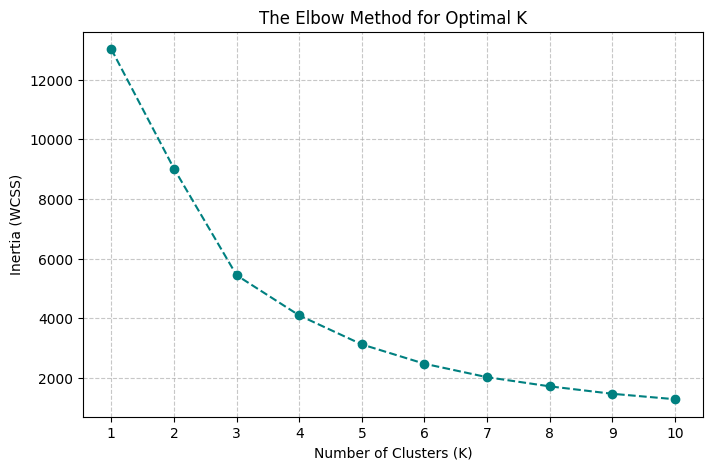

In [4]:
import os

# This environment variable silences the missing 'wmic' warning in Windows 11
os.environ['LOKY_MAX_CPU_COUNT'] = '4' 

# Compute Within-Cluster Sum of Squares (WCSS / Inertia) for K = 1 to 10
inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='--', color='teal')
plt.title('The Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (WCSS)')
plt.xticks(K_range)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

C:\Users\dp185\AppData\Local\Temp\ipykernel_17084\3348657491.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=rfm, x='Cluster', palette='tab10')


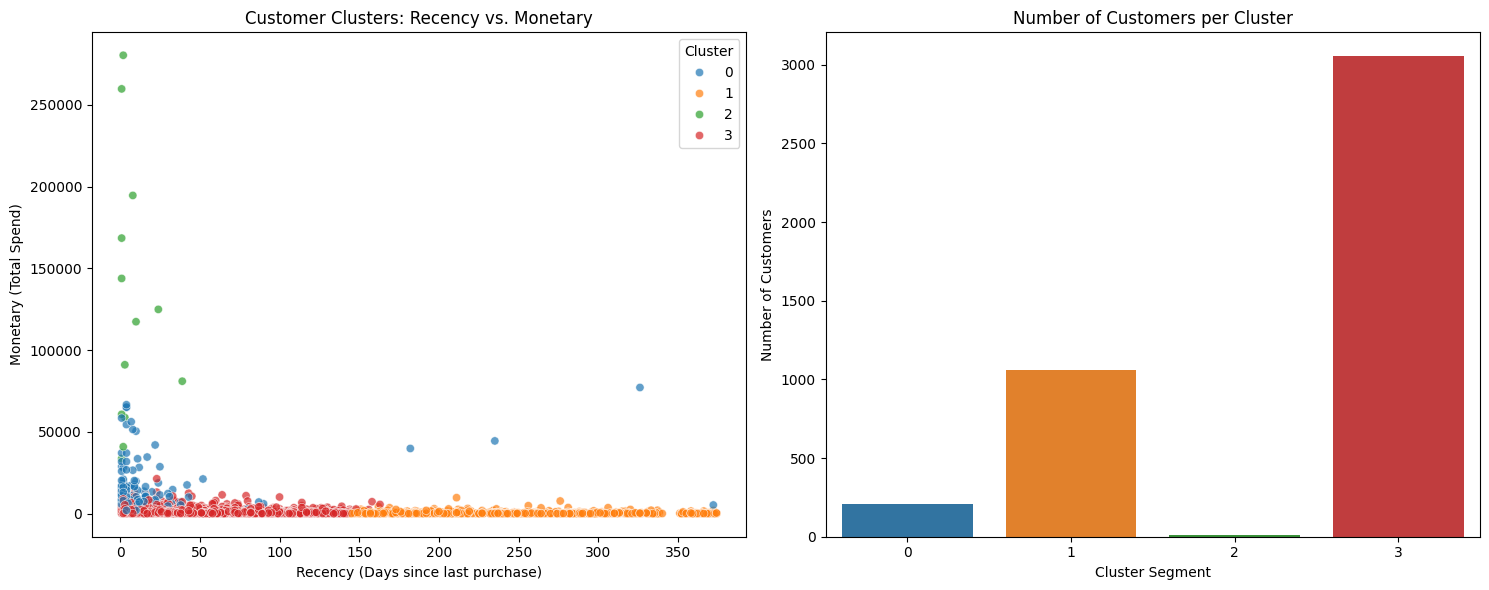

--- Cluster Profiles (Mean Values) ---


,Recency,Frequency,Monetary,Customer Count
Cluster,,,,
0,15.67,22.05,12453.23,211
1,248.56,1.55,478.11,1062
2,7.38,82.69,127338.31,13
3,43.91,3.66,1349.70,3053


In [5]:
# 1. Fit K-Means with the optimal number of clusters (K=4)
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)

# Assign the resulting cluster labels back to our original (unscaled) RFM dataframe
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

# Set up the matplotlib figure
plt.figure(figsize=(15, 6))

# 2. Scatter Plot: Recency vs Monetary
plt.subplot(1, 2, 1)
sns.scatterplot(data=rfm, x='Recency', y='Monetary', hue='Cluster', palette='tab10', alpha=0.7)
plt.title('Customer Clusters: Recency vs. Monetary')
plt.xlabel('Recency (Days since last purchase)')
plt.ylabel('Monetary (Total Spend)')

# 3. Bar Chart: Number of customers per cluster
plt.subplot(1, 2, 2)
sns.countplot(data=rfm, x='Cluster', palette='tab10')
plt.title('Number of Customers per Cluster')
plt.xlabel('Cluster Segment')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

# 4. Profile each cluster by calculating the mean values
cluster_profile = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'
}).round(2)

# Add the count of customers to the profile
cluster_profile['Customer Count'] = rfm['Cluster'].value_counts()

print("--- Cluster Profiles (Mean Values) ---")
display(cluster_profile)

### Customer Segmentation Insights & Recommended Marketing Actions

Based on the K-Means clustering ($K=4$) of the RFM features, the customer base has been segmented into four distinct behavioral profiles:

1. **Cluster 2 — VIP / Enterprise Clients (13 customers):**
   * **Profile:** Highest monetary value (avg. $127,338 spend), highest purchase frequency (82+ orders), and highly active (avg. recency 7.4 days).
   * **Marketing Strategy:** White-glove treatment. Assign dedicated account managers, provide early access to new catalog lines, and offer tailored corporate discounts. Retention is paramount here.

2. **Cluster 0 — Loyal High-Spenders (211 customers):**
   * **Profile:** High spend (avg. $12,453) and frequent repeat buyers (22 orders) with recent transactions (avg. recency 15.7 days).
   * **Marketing Strategy:** Loyalty reward programs, premium tier memberships, and personalized cross-selling/upselling recommendations to keep engagement high.

3. **Cluster 3 — Regular Core Buyers (3,053 customers):**
   * **Profile:** The largest customer cohort. Moderate spend (avg. $1,350), low-to-moderate frequency (3.7 orders), and active within the last 44 days.
   * **Marketing Strategy:** Volume-incentive campaigns (e.g., "Spend $X, get $Y off" or bundled offers) and cart-abandonment nudges to convert them into higher-frequency buyers.

4. **Cluster 1 — At-Risk / Hibernating Customers (1,062 customers):**
   * **Profile:** Longest recency (avg. 248.6 days since last purchase), lowest frequency (1.5 orders), and lowest spend ($478).
   * **Marketing Strategy:** Automated win-back / reactivation email campaigns featuring limited-time discount codes or feedback surveys to identify why they stopped purchasing.